# NMR - Free Induction Decay

> Part of *PHYS 0241: Biomedical Imaging* (Prof. Michael E. Durst, Middlebury College). The [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch10/ch10-02.html) shows the rendered version together with the pre-rendered animations (course password required).
>
> **Start here:** run the setup cell below first. In Google Colab, choose **File > Save a copy in Drive** to keep your changes.
>
> *Provided for academic use in PHYS 0241; please do not repost or redistribute ([terms of use](https://github.com/durstme/textbook-biomedicalimaging-notebooks/blob/main/LICENSE.md)).*

In [ ]:
# --- Setup: run this cell first.  It does nothing outside Google Colab. ---
import sys, os, importlib.util, urllib.request
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # interactive matplotlib (%matplotlib widget) needs ipympl and Colab's custom widget manager
    if importlib.util.find_spec("ipympl") is None:
        get_ipython().run_line_magic("pip", "install -q ipympl")
        importlib.invalidate_caches()  # make the freshly installed package importable
        try:  # matplotlib caches its backend list on first use; refresh it so no restart is needed
            from matplotlib.backends.registry import backend_registry
            backend_registry._clear()
        except Exception:
            pass
    import ipympl  # noqa: F401
    from google.colab import output
    output.enable_custom_widget_manager()
    print("Colab setup done. If a %matplotlib widget cell still errors, use Runtime > Restart session, then Run all.")

## Import libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.integrate import odeint

## Define parameters

In [2]:
# ==========================================
# 1. PARAMETERS & CONSTANTS
# ==========================================
Gamma = 268.0        # Gyromagnetic ratio
T1 = 100000.0        # Longitudinal relaxation
T2 = 100000.0        # Transverse relaxation
TE = 4000.0          # Echo time / delay base unit
B1_amp = 0.0004      # RF Amplitude
M0 = 1.0             # Equilibrium magnetization

# Calculate durations based on flip angles
# 90 degree pulse duration: pi / (2 * Gamma * B1)
duration90 = np.pi / (2.0 * Gamma * B1_amp)
# The experiment intervals (Pulse ON -> Wait -> Wait...)
time_intervals = [duration90, TE/2, TE, TE, TE, TE]

# Off-resonance parameters (Simulating Inhomogeneity)
n_spins = 19
# Create symmetric offsets: centered at 0
indices = np.arange(1, n_spins + 1)
excess_B0_values = 0.0000005 * ((n_spins + 1)/2.0 - indices)

# ==========================================
# 2. PHYSICS ENGINE (BLOCH EQUATIONS)
# ==========================================

def bloch_equations(M_flat, t, B1_val, offsets):
    """
    Computes dM/dt for N spins.
    """
    # Reshape to (N, 3) for vector math
    M = M_flat.reshape((n_spins, 3))
    dMdt = np.zeros_like(M)
    
    # Extract components
    Mx, My, Mz = M[:, 0], M[:, 1], M[:, 2]
    
    # B-field vector (Rotating Frame)
    Bx = np.full(n_spins, B1_val)
    By = np.zeros(n_spins)
    Bz = offsets # Local inhomogeneity
    
    # Cross Product: Gamma * (M x B)
    cross_x = My * Bz - Mz * By
    cross_y = Mz * Bx - Mx * Bz
    cross_z = Mx * By - My * Bx
    
    # Relaxation
    relax_x = -Mx / T2
    relax_y = -My / T2
    relax_z = (1.0 - Mz) / T1 
    
    dMdt[:, 0] = Gamma * cross_x + relax_x
    dMdt[:, 1] = Gamma * cross_y + relax_y
    dMdt[:, 2] = Gamma * cross_z + relax_z
    
    return dMdt.flatten()

# --- Simulation Steps ---

# 1. Pulse ON (Interval 0)
# We use 20 points exactly so frame 20 lands at the end of the pulse
t_pulse = np.linspace(0, duration90, 20)
M_init = np.zeros((n_spins, 3))
M_init[:, 2] = 1.0 # All start at +Z
M_init_flat = M_init.flatten()

sol_pulse = odeint(bloch_equations, M_init_flat, t_pulse, args=(B1_amp, excess_B0_values))

# 2. Pulse OFF (Free Precession/Decay)
t_decay_start = duration90
t_decay_end = sum(time_intervals)
t_decay = np.linspace(t_decay_start, t_decay_end, 300)

# Initial condition is the end of the pulse
M_decay_start = sol_pulse[-1, :]
sol_decay = odeint(bloch_equations, M_decay_start, t_decay, args=(0.0, excess_B0_values))

# Combine Data
all_t = np.concatenate((t_pulse, t_decay[1:])) 
all_M_flat = np.concatenate((sol_pulse, sol_decay[1:]))
all_M = all_M_flat.reshape((len(all_t), n_spins, 3))

# --- Calculate Derived Data ---
net_M = np.mean(all_M, axis=1) 
net_Mxy_mag = np.sqrt(net_M[:, 0]**2 + net_M[:, 1]**2)
net_Mz = net_M[:, 2]

# Pulse shape for plotting
pulse_profile = np.zeros_like(all_t)
pulse_profile[all_t <= duration90] = 1.0



## Plot

Plotting Frame: 40
Time: 1278.8670s


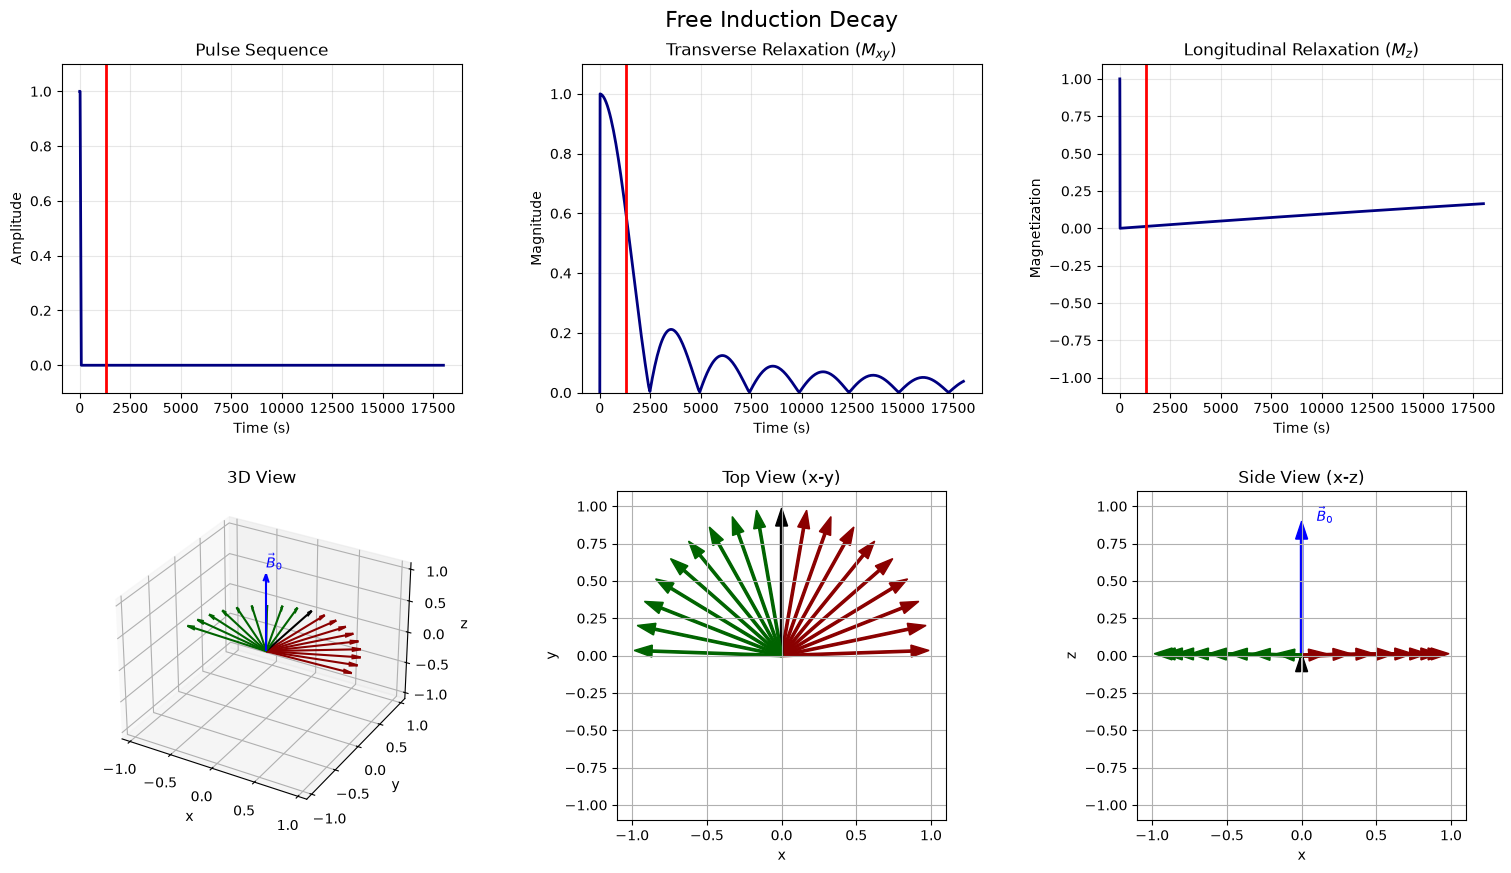

In [3]:
# ==========================================
# 3. VISUALIZATION
# ==========================================

fig1 = plt.figure(figsize=(16, 9))
plt.subplots_adjust(left=0.05, right=0.95, top=0.92, bottom=0.08, wspace=0.3, hspace=0.3)
fig1.suptitle("Free Induction Decay", fontsize=16)

# --- Define Axes ---
# Row 1
ax_pulse = fig1.add_subplot(2, 3, 1)
ax_mxy   = fig1.add_subplot(2, 3, 2)
ax_mz    = fig1.add_subplot(2, 3, 3)

# Row 2
ax_3d    = fig1.add_subplot(2, 3, 4, projection='3d')
ax_top   = fig1.add_subplot(2, 3, 5)
ax_side  = fig1.add_subplot(2, 3, 6)

# --- Static Setup ---

# 1. Pulse Plot
ax_pulse.plot(all_t, pulse_profile, color='navy', lw=2)
ax_pulse.set_title("Pulse Sequence")
ax_pulse.set_ylim(-0.1, 1.1)
ax_pulse.set_xlabel("Time (s)")
ax_pulse.set_ylabel("Amplitude")
ax_pulse.grid(True, alpha=0.3)
line_marker_pulse = ax_pulse.axvline(0, color='red', lw=2)

# 2. Transverse Magnetization
ax_mxy.plot(all_t, net_Mxy_mag, color='navy', lw=2)
ax_mxy.set_title("Transverse Relaxation ($M_{xy}$)")
ax_mxy.set_ylim(0, 1.1)
ax_mxy.set_xlabel("Time (s)")
ax_mxy.set_ylabel("Magnitude")
ax_mxy.grid(True, alpha=0.3)
line_marker_mxy = ax_mxy.axvline(0, color='red', lw=2)

# 3. Longitudinal Magnetization
ax_mz.plot(all_t, net_Mz, color='navy', lw=2)
ax_mz.set_title("Longitudinal Relaxation ($M_z$)")
ax_mz.set_ylim(-1.1, 1.1)
ax_mz.set_xlabel("Time (s)")
ax_mz.set_ylabel("Magnetization")
ax_mz.grid(True, alpha=0.3)
line_marker_mz = ax_mz.axvline(0, color='red', lw=2)

# Helper for Frame Views
def setup_view_ax(ax, title, xlabel, ylabel, is_3d=False):
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_xlim(-1.1, 1.1)
    ax.set_ylim(-1.1, 1.1)
    if is_3d:
        ax.set_zlim(-1.1, 1.1)
        ax.set_zlabel("z")
        # Static B0
        ax.quiver(0, 0, 0, 0, 0, 1, color='blue', length=1.2, arrow_length_ratio=0.1)
        ax.text(0, 0, 1.3, r'$\vec{B}_0$', color='blue', fontweight='bold')
    else:
        ax.grid(True)
        ax.set_aspect('equal', 'box')
        if 'z' in ylabel: # Side View B0
             ax.arrow(0, 0, 0, 0.9, width=0.015, head_width=0.08, color='blue', length_includes_head=True)
             ax.text(0.1, 0.9, r'$\vec{B}_0$', color='blue')

setup_view_ax(ax_3d, "3D View", "x", "y", is_3d=True)
setup_view_ax(ax_top, "Top View (x-y)", "x", "y")
setup_view_ax(ax_side, "Side View (x-z)", "x", "z")

# --- Objects for Updating ---

quiver_3d = None
quivers_top = []
quivers_side = []

# Initialize dummy arrows to populate lists
colors = []
mid_idx = (n_spins - 1) // 2
for i in range(n_spins):
    if i < mid_idx: c = 'darkred'
    elif i == mid_idx: c = 'black'
    else: c = 'darkgreen'
    colors.append(c)
    
    # We initialize with dummy arrows that will be removed immediately in the update
    q_top = ax_top.arrow(0, 0, 0, 0, color='none')
    quivers_top.append(q_top)
    q_side = ax_side.arrow(0, 0, 0, 0, color='none')
    quivers_side.append(q_side)

# --- Update Function ---

def update(frame):
    global quiver_3d, quivers_top, quivers_side
    
    # Ensure frame is within bounds
    if frame >= len(all_t):
        frame = len(all_t) - 1
        
    current_time = all_t[frame]
    current_M = all_M[frame]
    
    # 1. Update Vertical Markers
    line_marker_pulse.set_xdata([current_time])
    line_marker_mxy.set_xdata([current_time])
    line_marker_mz.set_xdata([current_time])
    
    # 2. Update 3D Plot
    if quiver_3d:
        quiver_3d.remove()
    
    us = current_M[:, 0]
    vs = current_M[:, 1]
    ws = current_M[:, 2]
    xs = np.zeros(n_spins)
    ys = np.zeros(n_spins)
    zs = np.zeros(n_spins)
    
    quiver_3d = ax_3d.quiver(xs, ys, zs, us, vs, ws, color=colors, arrow_length_ratio=0.1)
    
    # 3. Update 2D Plots
    # Remove old arrows
    for q in quivers_top: q.remove()
    for q in quivers_side: q.remove()
    quivers_top.clear()
    quivers_side.clear()
    
    for i in range(n_spins):
        mx, my, mz = current_M[i]
        c = colors[i]
        
        # Top View (Mx, My)
        if np.hypot(mx, my) > 0.001:
            q_t = ax_top.arrow(0, 0, mx, my, width=0.015, head_width=0.08, 
                               length_includes_head=True, color=c)
            quivers_top.append(q_t)
        else:
            q_t = ax_top.arrow(0, 0, 0, 0, width=0.0, color='none') 
            quivers_top.append(q_t)

        # Side View (Mx, Mz)
        if np.hypot(mx, mz) > 0.001:
            q_s = ax_side.arrow(0, 0, mx, mz, width=0.015, head_width=0.08, 
                                length_includes_head=True, color=c)
            quivers_side.append(q_s)
        else:
             q_s = ax_side.arrow(0, 0, 0, 0, width=0.0, color='none')
             quivers_side.append(q_s)

# ==========================================
# 4. PLOT SPECIFIC FRAME
# ==========================================
frame_to_plot = 40

print(f"Plotting Frame: {frame_to_plot}")
print(f"Time: {all_t[frame_to_plot]:.4f}s")

# Call update once to render the specific frame
update(frame_to_plot)

# Show the static figure
plt.show()

## Animation

In [4]:
# ==========================================
# 0. SETUP & MAGIC COMMANDS
# ==========================================
%matplotlib widget

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.integrate import odeint
import ipywidgets as widgets
from IPython.display import display

# Clear old plots to free up memory
plt.close('all')

# THE FIX: Turn off Matplotlib's auto-display so it doesn't double-render
plt.ioff()

# ==========================================
# 1. PARAMETERS & CONSTANTS
# ==========================================
Gamma2 = 268.0        # Gyromagnetic ratio
T1_2 = 100000.0        # Longitudinal relaxation
T2_2 = 100000.0        # Transverse relaxation
TE2 = 4000.0          # Echo time / delay base unit
B1_amp2 = 0.0004      # RF Amplitude

# Calculate durations based on flip angles
duration90_2 = np.pi / (2.0 * Gamma2 * B1_amp2)
time_intervals2 = [duration90_2, TE2/2, TE2, TE2, TE2, TE2]
total_duration = sum(time_intervals2)

# Off-resonance parameters (Simulating Inhomogeneity)
n_spins2 = 19
indices2 = np.arange(1, n_spins2 + 1)
excess_B0_values2 = 0.0000005 * ((n_spins2 + 1)/2.0 - indices2)

# ==========================================
# 2. PHYSICS ENGINE (BLOCH EQUATIONS)
# ==========================================
def bloch_equations2(M_flat, t, B1_val, offsets):
    M = M_flat.reshape((n_spins2, 3))
    dMdt = np.zeros_like(M)
    
    Mx, My, Mz = M[:, 0], M[:, 1], M[:, 2]
    
    Bx = np.full(n_spins2, B1_val)
    By = np.zeros(n_spins2)
    Bz = offsets 
    
    cross_x = My * Bz - Mz * By
    cross_y = Mz * Bx - Mx * Bz
    cross_z = Mx * By - My * Bx
    
    relax_x = -Mx / T2_2
    relax_y = -My / T2_2
    relax_z = (1.0 - Mz) / T1_2 
    
    dMdt[:, 0] = Gamma2 * cross_x + relax_x
    dMdt[:, 1] = Gamma2 * cross_y + relax_y
    dMdt[:, 2] = Gamma2 * cross_z + relax_z
    
    return dMdt.flatten()

# --- Simulation Steps ---
t_pulse2 = np.linspace(0, duration90_2, 20)
M_init2 = np.zeros((n_spins2, 3))
M_init2[:, 2] = 1.0
M_init_flat2 = M_init2.flatten()

sol_pulse2 = odeint(bloch_equations2, M_init_flat2, t_pulse2, args=(B1_amp2, excess_B0_values2))

t_decay_start2 = duration90_2
t_decay_end2 = sum(time_intervals2)
t_decay2 = np.linspace(t_decay_start2, t_decay_end2, 300)

M_decay_start2 = sol_pulse2[-1, :]
sol_decay2 = odeint(bloch_equations2, M_decay_start2, t_decay2, args=(0.0, excess_B0_values2))

# Combine Data
all_t2 = np.concatenate((t_pulse2, t_decay2[1:])) 
all_M_flat2 = np.concatenate((sol_pulse2, sol_decay2[1:]))
all_M2 = all_M_flat2.reshape((len(all_t2), n_spins2, 3))

net_M2 = np.mean(all_M2, axis=1) 
net_Mxy_mag2 = np.sqrt(net_M2[:, 0]**2 + net_M2[:, 1]**2)
net_Mz2 = net_M2[:, 2]

pulse_profile2 = np.zeros_like(all_t2)
pulse_profile2[all_t2 <= duration90_2] = 1.0

# ==========================================
# 3. VISUALIZATION SETUP
# ==========================================
fig = plt.figure(figsize=(10, 6))
fig.canvas.header_visible = False # Hides the default ipympl header
plt.subplots_adjust(left=0.05, right=0.95, top=0.90, bottom=0.08, wspace=0.3, hspace=0.4)
fig.suptitle("Free Induction Decay", fontsize=16)

# --- Define Axes ---
ax_pulse2 = fig.add_subplot(2, 3, 1)
ax_mxy2   = fig.add_subplot(2, 3, 2)
ax_mz2    = fig.add_subplot(2, 3, 3)
ax_3d2    = fig.add_subplot(2, 3, 4, projection='3d')
ax_top2   = fig.add_subplot(2, 3, 5)
ax_side2  = fig.add_subplot(2, 3, 6)

# --- Static Setup ---
ax_pulse2.plot(all_t2, pulse_profile2, color='navy', lw=2)
ax_pulse2.set_title("Pulse Sequence")
ax_pulse2.set_ylim(-0.1, 1.1)
ax_pulse2.grid(True, alpha=0.3)
line_marker_pulse2 = ax_pulse2.axvline(0, color='red', lw=2)

ax_mxy2.plot(all_t2, net_Mxy_mag2, color='navy', lw=2)
ax_mxy2.set_title("Transverse Relaxation ($M_{xy}$)")
ax_mxy2.set_ylim(0, 1.1)
ax_mxy2.grid(True, alpha=0.3)
line_marker_mxy2 = ax_mxy2.axvline(0, color='red', lw=2)

ax_mz2.plot(all_t2, net_Mz2, color='navy', lw=2)
ax_mz2.set_title("Longitudinal Relaxation ($M_z$)")
ax_mz2.set_ylim(-1.1, 1.1)
ax_mz2.grid(True, alpha=0.3)
line_marker_mz2 = ax_mz2.axvline(0, color='red', lw=2)

def setup_view_ax2(ax, title, xlabel, ylabel, is_3d=False):
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_xlim(-1.1, 1.1)
    ax.set_ylim(-1.1, 1.1)
    if is_3d:
        ax.set_zlim(-1.1, 1.1)
        ax.set_zlabel("z")
        ax.quiver(0, 0, 0, 0, 0, 1.2, color='blue', length=1.0, arrow_length_ratio=0.1)
        ax.text(0, 0, 1.3, r'$\vec{B}_0$', color='blue', fontweight='bold')
    else:
        ax.grid(True)
        ax.set_aspect('equal', 'box')

setup_view_ax2(ax_3d2, "3D View", "x", "y", is_3d=True)
setup_view_ax2(ax_top2, "Top View (x-y)", "x", "y")
setup_view_ax2(ax_side2, "Side View (x-z)", "x", "z")

# Side View static B0
ax_side2.quiver(0, 0, 0, 0.9, color='blue', scale=1, scale_units='xy', angles='xy', width=0.01)
ax_side2.text(0.1, 0.9, r'$\vec{B}_0$', color='blue')

# --- Initialize Vector Collections ---
colors2 = ['darkred' if i < n_spins2//2 else 'black' if i == n_spins2//2 else 'darkgreen' for i in range(n_spins2)]
zeros = np.zeros(n_spins2)

# 2D Quivers
q_top2 = ax_top2.quiver(zeros, zeros, zeros, zeros, color=colors2, scale=1, scale_units='xy', angles='xy', width=0.01)
q_side2 = ax_side2.quiver(zeros, zeros, zeros, zeros, color=colors2, scale=1, scale_units='xy', angles='xy', width=0.01)

# 3D Quiver
q_3d = None

# ==========================================
# 4. INTERACTIVITY LOGIC & WIDGETS
# ==========================================
def update_plot(change):
    global q_3d
    frame = change['new']
    current_time = all_t2[frame]
    current_M = all_M2[frame]
    
    # 1. Update timeline markers
    line_marker_pulse2.set_xdata([current_time])
    line_marker_mxy2.set_xdata([current_time])
    line_marker_mz2.set_xdata([current_time])
    
    # 2. Update 2D vectors
    q_top2.set_UVC(current_M[:, 0], current_M[:, 1])
    q_side2.set_UVC(current_M[:, 0], current_M[:, 2])
    
    # 3. Update 3D vectors
    if q_3d is not None:
        q_3d.remove()
    q_3d = ax_3d2.quiver(zeros, zeros, zeros, 
                        current_M[:, 0], current_M[:, 1], current_M[:, 2], 
                        color=colors2, arrow_length_ratio=0.1)
    
    # 4. Push updates to the UI
    fig.canvas.draw_idle()

# Create UI Widgets
anim_stride = 2 
play = widgets.Play(value=0, min=0, max=len(all_t2)-1, step=anim_stride, interval=50, description="Press play")
slider = widgets.IntSlider(value=0, min=0, max=len(all_t2)-1, step=1, description='Frame:', layout=widgets.Layout(width='60%'))

# Link buttons and observe
widgets.jslink((play, 'value'), (slider, 'value'))
slider.observe(update_plot, names='value')

# Trigger the first frame render
update_plot({'new': 0})

# Package the controls
controls = widgets.HBox([play, slider], layout=widgets.Layout(justify_content='center', margin='10px 0px'))

# Explicitly display only the single widget canvas and controls
display(fig.canvas)
display(controls)

# Turn interactive mode back on for future cells
plt.ion()

### Display animation with javascript from standalone html
[Link to animation](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch10/ch10-02_animation.html)

*Animation.* The pre-rendered animation for this section is shown on the [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch10/ch10-02.html) (direct link: [ch10-02_animation.html](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch10/ch10-02_animation.html)). It is not embedded here because Colab cannot load files from the textbook site; running the code above produces the live version.